### Загрузка датасета

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/shopease_raw_orders.csv")

### Построение диаграммы доли пропусков

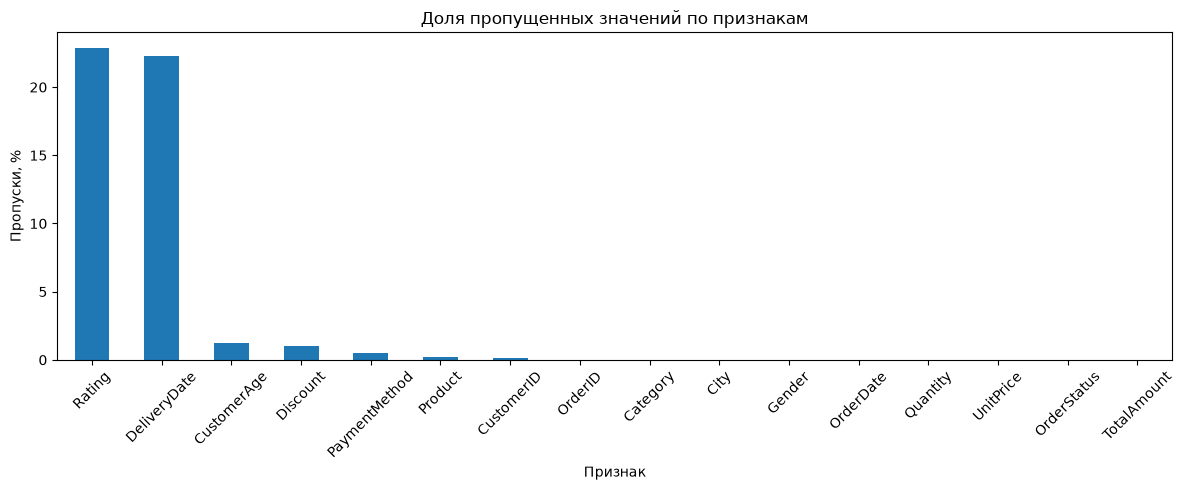

In [6]:
missing_percent = df.isna().mean().mul(100).sort_values(ascending=False)

ax = missing_percent.plot(kind="bar", figsize=(12, 5))
ax.set_title("Доля пропущенных значений по признакам")
ax.set_xlabel("Признак")
ax.set_ylabel("Пропуски, %")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

### Расчёт пропусков по объектам

In [8]:
missing_per_row = df.isna().sum(axis=1)

print(f"Всего объектов: {len(df)}")
print(f"Объектов без пропусков: {(missing_per_row == 0).sum()} ({(missing_per_row == 0).mean():.1%})")
print(f"Объектов с пропусками: {(missing_per_row > 0).sum()} ({(missing_per_row > 0).mean():.1%})")
print(f"Объектов, полностью состоящих из пропусков: {(missing_per_row == df.shape[1]).sum()}")
print(f"Максимум пропусков в одной строке: {missing_per_row.max()}")

Всего объектов: 10020
Объектов без пропусков: 7470 (74.6%)
Объектов с пропусками: 2550 (25.4%)
Объектов, полностью состоящих из пропусков: 0
Максимум пропусков в одной строке: 3


### Распределение числа пропусков по объектам

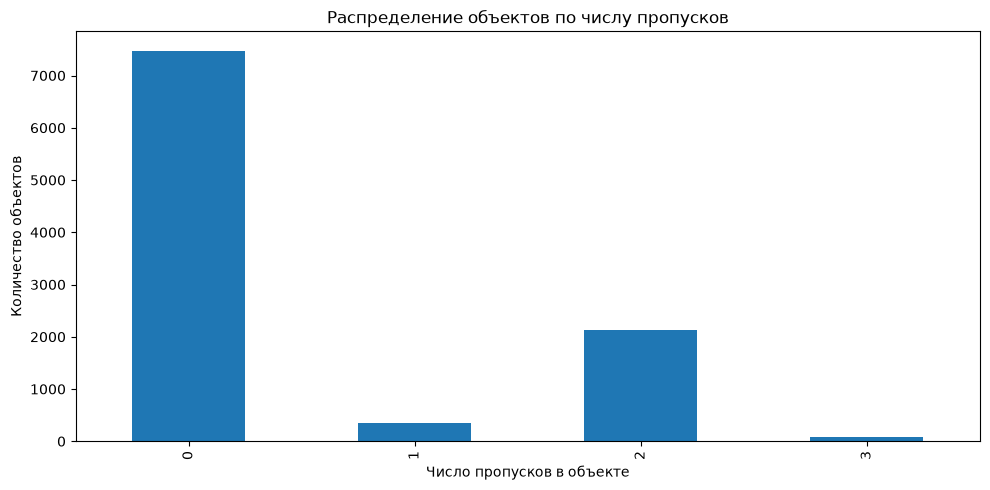

In [9]:
row_missing_counts = missing_per_row.value_counts().sort_index()

ax = row_missing_counts.plot(kind="bar", figsize=(10, 5))
ax.set_title("Распределение объектов по числу пропусков")
ax.set_xlabel("Число пропусков в объекте")
ax.set_ylabel("Количество объектов")
plt.tight_layout()
plt.show()

### Примеры объектов с пропусками

In [10]:
incomplete_rows = df.loc[missing_per_row > 0].copy()
incomplete_rows.insert(0, "Число пропусков", missing_per_row[missing_per_row > 0])
display(incomplete_rows.head(10))

,Число пропусков,OrderID,CustomerID,OrderDate,CustomerAge,Gender,City,Category,Product,Quantity,UnitPrice,Discount,PaymentMethod,OrderStatus,DeliveryDate,Rating,TotalAmount
9,2,13145,C0967,2026-03-18 16:44:00,49.0,Female,Mansoura,Home,Lamp,3,300,0.2,Cash,Pending,NaN,NaN,720.0
13,2,11052,C1844,2026-01-28 03:51:00,35.0,Female,Giza,Home,Chair,4,2500,0.0,Wallet,Pending,NaN,NaN,10000.0
15,1,17682,C1803,2026-02-22 06:22:00,20.0,Female,Mansoura,Electronics,Keyboard,4,900,NaN,Mastercard,Delivered,2026-02-26 06:22:00,2.0,3240.0
20,2,15029,C0598,2026-06-15 22:10:00,20.0,Female,Cairo,Home,Coffee Maker,1,1800,0.15,Visa,Cancelled,NaN,NaN,1530.0
32,2,16133,C1275,2026-05-07 03:00:00,47.0,Female,Cairo,Fashion,Jeans,4,900,0.1,Visa,Cancelled,NaN,NaN,3240.0
35,1,19229,NaN,2026-03-30 17:37:00,19.0,Male,Mansoura,Sports,Football,2,650,0.1,Bank Transfer,Delivered,2026-04-03 17:37:00,5.0,1170.0
37,2,10433,C1091,2026-05-16 07:54:00,37.0,Female,Giza,Sports,Football,1,650,0.0,Bank Transfer,Pending,NaN,NaN,650.0
38,1,14828,C0252,2026-05-08 21:17:00,23.0,Male,Alexandria,Sports,Football,1,650,NaN,Wallet,Delivered,2026-05-09 21:17:00,3.0,650.0
40,2,15010,C1430,2026-04-24 23:22:00,68.0,Female,Mansoura,Fashion,Bag,2,750,0.15,Cash,Pending,NaN,NaN,1275.0
42,1,15574,C0189,2026-06-25 15:33:00,NaN,Male,Giza,Sports,Yoga Mat,1,600,0.15,Cash,Delivered,2026-06-27 15:33:00,4.0,510.0
